<a href="https://colab.research.google.com/github/ak33ni/DATA-201-Project-1/blob/main/Project_1_PShrestha_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.neighbors import KNeighborsClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

#reading the data
df=pd.read_csv('bank-full.csv')
df.head()

,"age;""job"";""marital"";""education"";""default"";""balance"";""housing"";""loan"";""contact"";""day"";""month"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""y"""
0,"58;""management"";""married"";""tertiary"";""no"";2143..."
1,"44;""technician"";""single"";""secondary"";""no"";29;""..."
2,"33;""entrepreneur"";""married"";""secondary"";""no"";2..."
3,"47;""blue-collar"";""married"";""unknown"";""no"";1506..."
4,"33;""unknown"";""single"";""unknown"";""no"";1;""no"";""n..."


In [ ]:
#reformatting dataframe variable
df=pd.read_csv('bank-full.csv',delimiter=";")

#resetting the index
df=df.reset_index(drop=True)

#save reformatted data separately
df.to_csv('bank_marketing.csv', index=False)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Part 1: Understand Your Problem


### 1. What does each row of your dataset represent? What is your response variable? What are its possible classes?

Each row of the Bank Marketing Dataset from [UC Irvine](https://archive.ics.uci.edu/dataset/222/bank+marketing) represents a customer of a bank. It includes data of customer information, like age, job, and education, and a record of how a bank marketing campaign was presented to the customer, like contact method and contact frequncy. The response variable is y, which is a one-hot encoded variable that indicates if the customer has subscribed to the term deposit  of the bank.

The response has two classes: yes, meaning the customer subscribed, and no, meaning the customer did not subscribe. This creates a binary classification problem there are only two outcomes to predict.

### 2. Select the predictors you believe could be useful for classification.
There are 17 variables in the dataset. They represent
age, job, marital status, education, account balance, credit in default, housing loan existance, personal loan existance, contact method, recent month and day of contact, duration of last contact, number of contacts in the campaign, days since last contact, and outcome of the previous campaign (if they subscribed).

Predictors useful for classification are those that are taken into account when the bank is choosing who to contact. They provide information that can help predict what type of customer is likely to subscribe or not. For example, duration of communication is not useful because it cannot predict anything until after the call happens, so it provides no information after analyzation.

In [ ]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


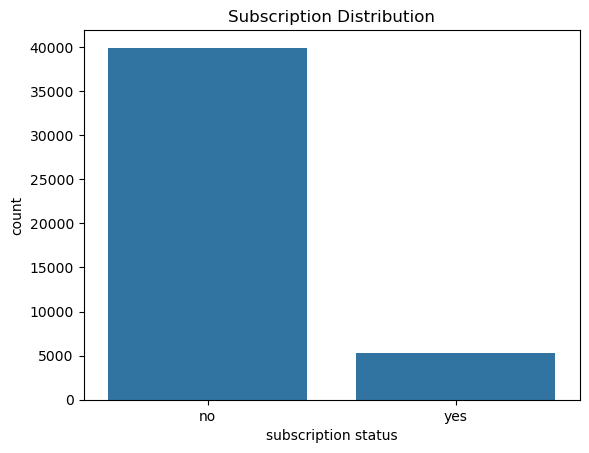

In [ ]:
print(df["y"].value_counts(normalize=True) * 100)
#Plot the response distribution:
sns.countplot(data=df, x="y")
plt.title("Subscription Distribution")
plt.xlabel("subscription status")
plt.show()

### 3. Examine the distribution of your response variable.

    - How many observations belong to each class?
    - Is the dataset reasonably balanced or imbalanced?
There are 39,922 customers subscribed and 5,289 not subscribed. When normailzed, that shows 88% of customers are subscribed compared to 12% not subscribed. The dataset is imbalanced because of the large difference in counts.

### 4. Define a false positive and false negative in the context of your dataset.
In this model, a false positive would be the prediction that a customer will subscribe, but they do not. The bank would work towards this customer's subscription without actually getting it, so it would be a waste.

A false negative would be the prediction that a customer will not subscribe, but they do. This would be a missed opportunity of a sale.

### 5. Which type of error would you be more concerned about in this application, or are they similarly important? Explain your reasoning.
A false positive would be more concerning if contacting a customer is too costly. If the bank is spending too much time per customer, the time lost on one false positive is basically money lost.

A false negative would be more concerning if contacting the customer is inexpensive and the profit from gaining a subscription is high. If they miss a customer, they miss a profitable opportunity.

The 'worse' outcome depends on the cost of customer contact and profit from subscription.

# Part 2: Explore and Prepare the Data

In [ ]:
# numerical variables
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
# categorical variable
df.describe(include="object")


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [ ]:
# missing values
df.isnull().sum()


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [ ]:
(df == 'unknown').sum()

age              0
job            288
marital          0
education     1857
default          0
balance          0
housing          0
loan             0
contact      13020
day              0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome     36959
y                0
dtype: int64

### 1. Investigate your features and predictors.
### 2. Determine whether your dataset contains missing values. If it does, explain how you handled them.
### 3. Determine whether any categorical predictors need to be encoded before modeling.


The Bank Marketing dataset has numerical and categorical predictors. I looked at the numerical predictors by using descriptive statistics and checked for null values.

The data contains no null values, but the categorical variables job, education, contact, and poutcome contained cell entries of "unknown", meaning that there is no information available or recorded. To handle these, I kept "unknown" as a separate category in the modelling instead of imputing values because of the high count of "unknown" entries. This ensures the dataset does not lose too much data.

Additionally, I one-hot encoded categorical predictors into numerical indicators before modelling since the analyses require numerical predictors.

In [ ]:
# Separate predictors and target
X = df.drop(columns=["y", "duration"])
y = df["y"]

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

# Identify feature types using training data
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

In [ ]:
print(categorical_features)
df[categorical_features].head()

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,job,marital,education,default,housing,loan,contact,month,poutcome
0,management,married,tertiary,no,yes,no,unknown,may,unknown
1,technician,single,secondary,no,yes,no,unknown,may,unknown
2,entrepreneur,married,secondary,no,yes,yes,unknown,may,unknown
3,blue-collar,married,unknown,no,yes,no,unknown,may,unknown
4,unknown,single,unknown,no,no,no,unknown,may,unknown


In [ ]:
# Standardize numerical predictors
numeric_process = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# One-hot encode categorical predictors
categorical_process = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    )
)

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_process, numeric_features),
    ("categorical", categorical_process, categorical_features)
])

In [ ]:
from sklearn.model_selection import train_test_split

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True))

Training set: (36168, 15)
Test set: (9043, 15)

Training class proportions:
y
no     0.883018
yes    0.116982
Name: proportion, dtype: float64

Test class proportions:
y
no     0.883003
yes    0.116997
Name: proportion, dtype: float64


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create the pipeline
log_model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000)
)

# Create five-fold cross-validation
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Run cross-validation on training data only
cv_scores = cross_val_score(
    log_model,
    X_train,
    y_train,
    cv=kfold,
    scoring="accuracy"
)

print("Five-fold CV accuracy scores:")
print(cv_scores)

print("Mean CV accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())


# Fit on the complete training set
log_model.fit(X_train, y_train)

# Evaluate on the untouched test set
test_accuracy = log_model.score(X_test, y_test)

print("Test accuracy:", test_accuracy)

Five-fold CV accuracy scores:
[0.88982582 0.89259054 0.89231407 0.89077838 0.89423476]
Mean CV accuracy: 0.8919487147673278
Standard deviation: 0.0015262886286334532
Test accuracy: 0.8933982085591065


### 4. Divide the data, then use k-fold CV on training data.
### 5. Determine whether predictors should be standardized for any of the classifiers you will  use.

I split the data into 80% training and 20% testing data. I used 5-fold cross validation on the training data, which creates 5 subsets of data so 4 can be used for training and 1 can be used for validation. Each subset is validated separately and the validation score is averaged. The testing data is untouched by training so it can be compared to the trained data.

Standardization changed numerical predictors to make them standard, which means they have a mean of 0 and a standard deviation of 1. This is important for classifiers that have very different ranges. For example, age and balance are recorded on very different scales. Age will almost always land between 0-100, but account balance can be negative or multiple figures higher than the highest age. Especially for K nearest-neighbros, high variance in ranges between variables can ruin the distance calcuations. In this case, standardization of predictors is very important. It also is useful in logistic regression but LDA and QDA do not require it.

I standardized the my predictors and will the same predictors for all the classifiers I build.

# Part 3: Build Your Classifiers
You will compare the four classification methods covered in DATA 201: Logistic Regression, LDA, QDA, KNN. Then choose the one that fits. Explain why you chose your classifier.


For Logistic Regression: Fit a logistic regression classifier using your training data. Report the model's test predictions and predicted probabilities.

For LDA: Fit an LDA classifier using the same training data and predictors. Generate predictions for the test data.

For QDA: Fit a QDA classifier using the same training data and predictors. Generate  predictions for the test data.

For KNN: KNN requires you to choose K. Do not simply choose a value. Use cross-validation on the training data to compare several reasonable values of K. Create a graph showing: K → Cross-validation performance. Which K did you select, and why? Then fit your final KNN classifier using that value.


### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Make predictions
log_pred = log_model.predict(X_test)

# Predict probabilities
log_prob = log_model.predict_proba(X_test)

# Find the column corresponding to "yes"
yes_index = list(log_model.classes_).index("yes")

# Probability of subscribing
log_prob_yes = log_prob[:, yes_index]

# Display results
print("Test accuracy:", accuracy_score(y_test, log_pred))

print("Confusion matrix:")
print(confusion_matrix(
    y_test,
    log_pred,
    labels=["no", "yes"]
))

# Display actual and predicted results
log_results = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': log_pred
})

display(log_results.head(10))


Test accuracy: 0.8933982085591065
Confusion matrix:
[[7894   91]
 [ 873  185]]


,Actual,Predicted
0,no,no
1,no,no
2,no,no
3,no,no
4,yes,no
5,no,no
6,no,no
7,no,no
8,no,no
9,no,no


### LDA

In [ ]:
# Linear Discriminant Analysis (LDA)

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
import pandas as pd

# Build the LDA model
lda_model = Pipeline([
    ('preprocessor', preprocessor),
    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x,
        accept_sparse=True
    )),
    ('classifier', LinearDiscriminantAnalysis())
])

# Train the model
lda_model.fit(X_train, y_train)

# Predict outcomes for the test data
lda_pred = lda_model.predict(X_test)

# Display actual and predicted results
lda_results = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': lda_pred
})

display(lda_results.head(10))


,Actual,Predicted
0,no,no
1,no,no
2,no,no
3,no,no
4,yes,no
5,no,no
6,no,no
7,no,no
8,no,no
9,no,no


### QDA

In [ ]:
# Quadratic Discriminant Analysis (QDA)

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
import pandas as pd

# Build the QDA model
qda_model = Pipeline([
    ('preprocessor', preprocessor),
    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x,
        accept_sparse=True
    )),
    ('classifier', QuadraticDiscriminantAnalysis(reg_param=0.1))
])

# Train the model
qda_model.fit(X_train, y_train)

# Predict outcomes for the test data
qda_pred = qda_model.predict(X_test)

# Display actual and predicted results
qda_results = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': qda_pred
})

display(qda_results.head(10))


,Actual,Predicted
0,no,no
1,no,no
2,no,no
3,no,no
4,yes,no
5,no,no
6,no,no
7,no,no
8,no,no
9,no,no


### KNN

In [ ]:

# K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd

# Values of K to test
k_values = [3, 5, 7, 9, 11, 15, 21]

# Set up 3-fold cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

knn_cv_scores = []

# Test each value of K
for k in k_values:
    knn_model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        knn_model, X_train, y_train,
        cv=cv, scoring='roc_auc'
    )

    knn_cv_scores.append(scores.mean())
    print(f"K = {k}, Mean ROC-AUC = {scores.mean():.4f}")

# Display results
knn_results = pd.DataFrame({
    'K': k_values,
    'Mean ROC-AUC': knn_cv_scores
})

display(knn_results)


K = 3, Mean ROC-AUC = 0.6645
K = 5, Mean ROC-AUC = 0.6922
K = 7, Mean ROC-AUC = 0.7043
K = 9, Mean ROC-AUC = 0.7162
K = 11, Mean ROC-AUC = 0.7210
K = 15, Mean ROC-AUC = 0.7313
K = 21, Mean ROC-AUC = 0.7384


,K,Mean ROC-AUC
0,3,0.664522
1,5,0.692200
2,7,0.704305
3,9,0.716177
4,11,0.720957
5,15,0.731347
6,21,0.738392


In [ ]:
# Select the K with the highest mean score
best_k = k_values[knn_cv_scores.index(max(knn_cv_scores))]
print("Selected K:", best_k)
print("Best CV ROC-AUC:", max(knn_cv_scores))


Selected K: 21
Best CV ROC-AUC: 0.7383919026609079


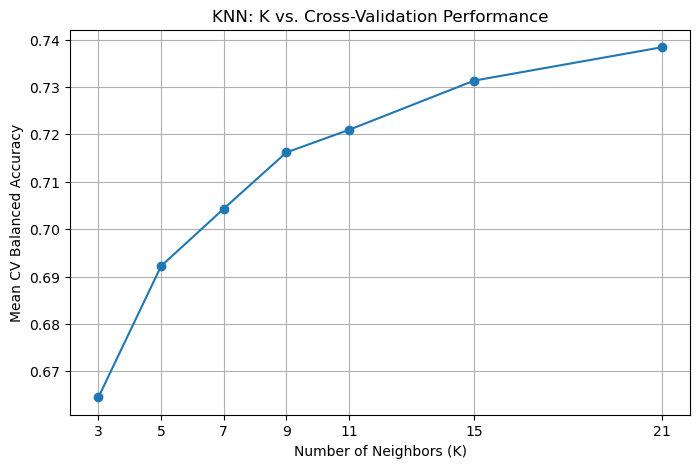

KNN Test Accuracy: 0.8894172287957536
KNN Confusion Matrix:
[[7911   74]
 [ 926  132]]


,Actual,Predicted
0,no,no
1,no,no
2,no,no
3,no,no
4,yes,no
5,no,no
6,no,no
7,no,no
8,no,no
9,no,no


In [ ]:
# Plot K versus cross-validation performance
plt.figure(figsize=(8, 5))
plt.plot(k_values, knn_cv_scores, marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Balanced Accuracy")
plt.title("KNN: K vs. Cross-Validation Performance")
plt.xticks(k_values)
plt.grid(True)
plt.show()


# Build the final KNN model using best K
knn_model = make_pipeline(
    preprocessor,
    KNeighborsClassifier(n_neighbors=best_k)
)

# Train the model
knn_model.fit(X_train, y_train)

# Predict outcomes for the test data
knn_pred = knn_model.predict(X_test)

# Display test accuracy
from sklearn.metrics import accuracy_score, confusion_matrix

print("KNN Test Accuracy:", accuracy_score(y_test, knn_pred))

print("KNN Confusion Matrix:")
print(confusion_matrix(
    y_test,
    knn_pred,
    labels=["no", "yes"]
))

# Display actual and predicted results
knn_results = pd.DataFrame({
    "Actual": pd.Series(y_test).to_numpy(),
    "Predicted": knn_pred
})

display(knn_results.head(10))

# Part 4: Evaluate your models

Logistic Regression
[[7894   91]
 [ 873  185]]


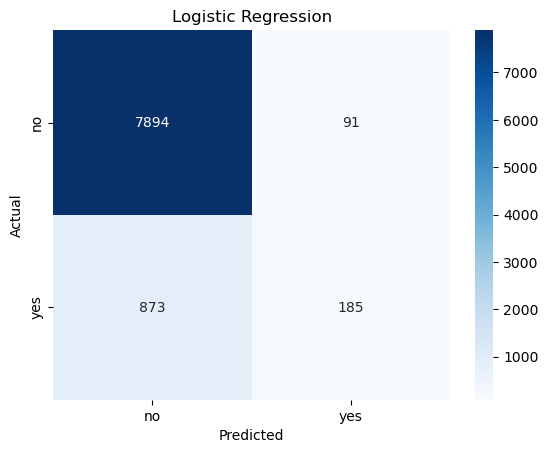

LDA
[[7741  244]
 [ 759  299]]


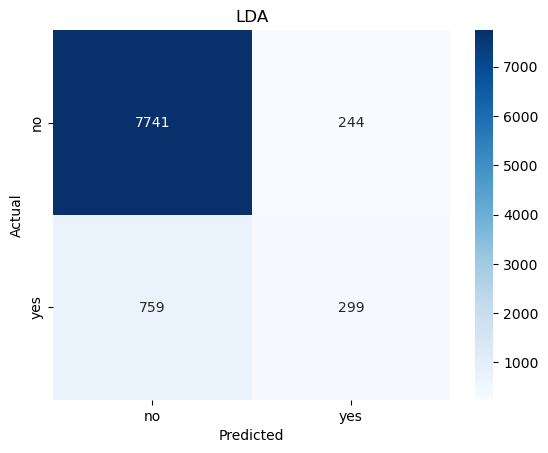

QDA
[[7669  316]
 [ 737  321]]


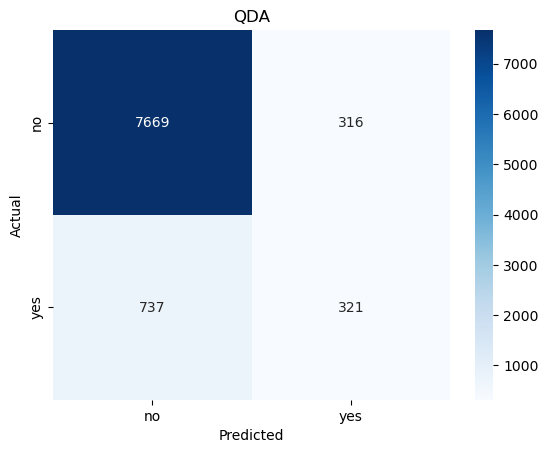

KNN
[[7911   74]
 [ 926  132]]


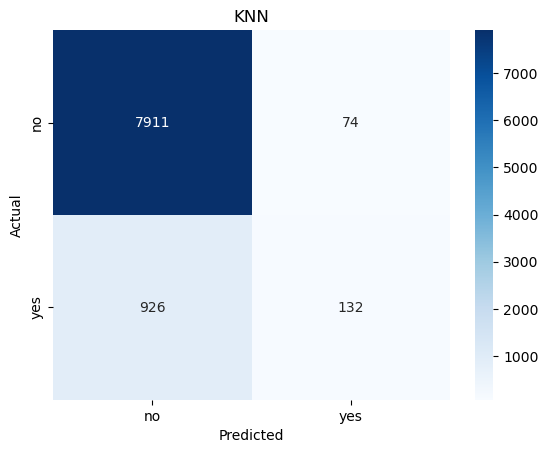

,Model,Accuracy,Precision,Recall/Sensitivity,Specificity,F1 Score,ROC-AUC
0,Logistic Regression,0.893,0.670,0.175,0.989,0.277,0.770
1,LDA,0.889,0.551,0.283,0.969,0.374,0.764
2,QDA,0.884,0.504,0.303,0.960,0.379,0.763
3,KNN,0.889,0.641,0.125,0.991,0.209,0.752


In [ ]:
# Choose threshold
threshold = 0.50

# Store the models
models = {
    "Logistic Regression": log_model,
    "LDA": lda_model,
    "QDA": qda_model,
    "KNN": knn_model
}

results = []

# Evaluate each model
for name, model in models.items():

    # Predict probabilities
    yes_index = list(model.classes_).index("yes")
    probabilities = model.predict_proba(X_test)[:, yes_index]

    # Predict classes using threshold
    predictions = np.where(probabilities >= threshold, "yes", "no")

    # Confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=["no", "yes"])
    tn, fp, fn, tp = cm.ravel()

    print(name)
    print(cm)

    # Plot confusion matrix
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["no", "yes"],
        yticklabels=["no", "yes"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name)
    plt.show()

    # Calculate metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "Recall/Sensitivity": recall_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (np.asarray(y_test) == "yes").astype(int),
            probabilities
        )
    })

# Display comparison table
evaluation_table = pd.DataFrame(results)
display(evaluation_table.round(3))

#

# Part 5: Reflect

The evaluation table shows all four models have high accuracy from 88.4% to 89.3%. Though, I have to believe this to be skewed because the values of subscribers and non-subscribers were not very balanced to begin with. Logistic Regression had the highest accuracy at 89.3%, then LDA and KNN at 88.9%, and finally QDA at 88.4%. Logistic regression also has the highest precision of 67%, which means its predictions of subscriptions are correct 67% of the time. It also has the highest ROC-AUC score of 77%, which means it has a strongest ability to actually separate subscriber and non-subscribers. Despite these, it has the second lowest recall at 17.5%, which means it only identifies a small percentage of subscribers.
Opposing this, QDA has the highest recall at 30.3%. This means that QDA identifies the highest percentage of actual subscribers, but also it has the highest false positives of all the models with 316 false positives. Compare that to Logistic Regression's 91, and that could be bad if the bank is highly affected by false positives.

Based on the consequences of false positives and false negatives, precision and recall are very useful. At the most basic level, false positives are concerning if contacting a customer is too costly and false negatives are concerning if contacting a customer is inexpensive and profit is very high. High precision is important for expensive contant because the bank wastes less since their predictions are precise. High recall is important for inexpensive contact because the opportunity for profit is worth a contact attempt.

Depending of the bank, either logistic regression or QDA could work well. QDA has the highest F1 score, which suggests that it has the best balance of precision and recall of all the models.

The bank should consider the cost of contacting a customer, the potential profit from a subscription, and the consequences of a missed sale before choosing a model. For this project, high accuracy is valued, so I would use Logistic Regression to predict whether a customer would be a subscriber.

# Part 6: ROC-AUC

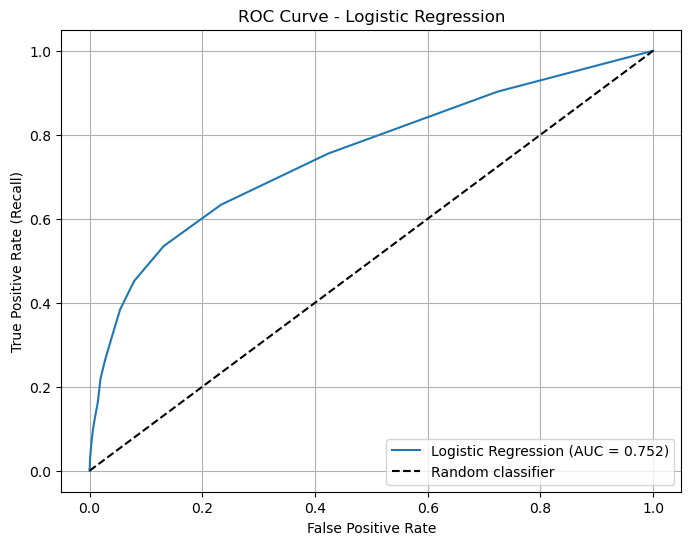

ROC-AUC: 0.752


In [ ]:
# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc_score = roc_auc_score(y_true, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("ROC-AUC:", round(auc_score, 3))

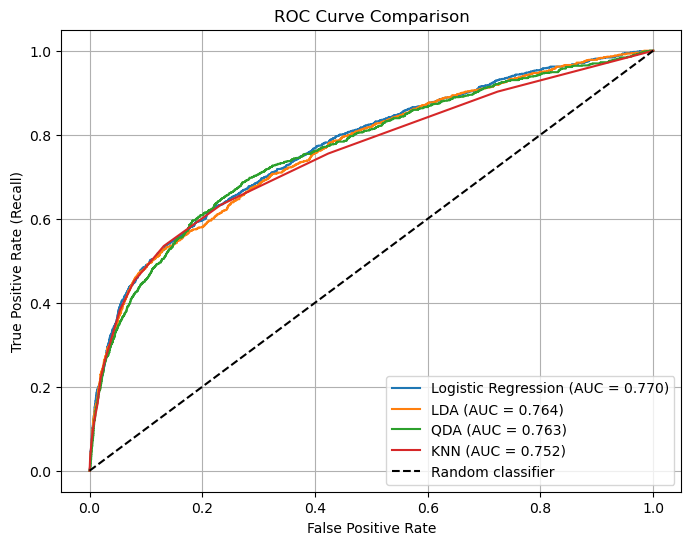

In [ ]:
y_true = (y_test == "yes").astype(int)

plt.figure(figsize=(8, 6))

for name, model in models.items():
    yes_index = list(model.classes_).index("yes")
    y_prob = model.predict_proba(X_test)[:, yes_index]

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    auc_score = roc_auc_score(y_true, y_prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

<Figure size 800x600 with 0 Axes>

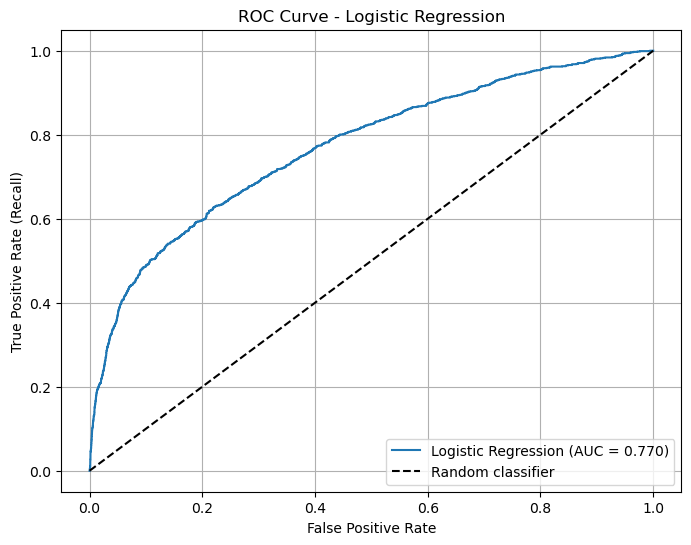

In [ ]:
y_true = (y_test == "yes").astype(int)

plt.figure(figsize=(8, 6))
yes_index = list(log_model.classes_).index("yes")
y_prob = log_model.predict_proba(X_test)[:, yes_index]

# Convert actual outcomes to binary values
y_true = (y_test == "yes").astype(int)

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc_score = roc_auc_score(y_true, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Part 7: Final Analysis
To answer the question 'How can we build and evaluate classification models to make predictions about a
real-world outcome?' and choosing the model with the highest accuracy, I classified the Bank Marketing dataset in four different ways. I trained the data by splitting it: 80% was trained to predict the target variable, whether a customer would subscribe to the bank's campaign, and 20% of the data was left alone. I ran the training data through four different models. All four of the classifiers, Logistic Regression, LDA, QDA, and KNN, had high, similarly valued accuracies, with Logistic Regression having the highest accuracy at 89.3%. High accuracy indicates that it was the most accurate overall and had the best ability in differentiating subscribers and non-subscribers across diffrent thresholds. However, the recall was only 17.5%, meaning it missed most actual subscribers. Logistic regression was better at identifying non-subscribers.

QDA had the lowest accuracy at 88.4% but the highest recall at 30.3%, meaning it identifiest the largest proportion of actual subscribers. Its F1 score was the highest of the four, 0.379, meaning it had the best balance of precision and recall. However, QDA had 316 false positives compared to logistic regression's 91.

The most important difference between logistic regression and QDA is finding potential subscribers and avoiding false predictions. Project 1 was looking for the highest accuracy, so logistic regression would be the choice classifier. For this dataset, prioritizing high accuracy might mean that the bank has high customer contact costs, so they want their predictions to be more accurate to not lose money.

If the bank wants to prioritize efficient marketing and minimize the cost of contacting customers who are unlikely to subscribe, they are looking for high accuracy. Logistic regression had the highest precision at 67.0%, the highest specificity at 98.9%, and the highest ROC-AUC at 0.770. These results suggest that Logistic Regression is a better choice when unnecessary contact attempts are expensive and the bank wants to target customers more selectively.

For the bank, before deploying either model, I would compare the financial cost of false positives with the potential profit lost through false negatives. I would also investigate whether adjusting the classification threshold could improve the results. Logistic Regression is my initial choice based on its overall performance and precision, but another bank's final decision should depend on the their own business objectives and the costs associated with each type of error.

One limitation is the class imbalance in the dataset. Approximately 88.3% of the observations belong to one response class and 11.7% to the other, and non-subscribers and the overwhelming majority. This imbalance can make accuracy misleading because a model can achieve high accuracy by predicting the majority class while failing to identify many actual subscribers. The large difference between the two response classes allow for more errors.

This limitation is visible in my results. Although all four models achieved accuracy close to 89%, all recall scores ranged from only 12.5% to 30.3%. This means that even the best model for identifying subscribers missed nearly 70% of actual subscribers. The high accuracy scores do not necessarily mean the models are effective at finding customers who are likely to subscribe, especially because of the highly imbalanced data of the target variable. In a real world situation, I would need to consider recall, precision, and ROC-AUC alongside accuracy when evaluating their usefulness.

Before using this model in a real marketing campaign, I would want more information about the financial costs and benefits of contacting customers. For example, I would want to know the average cost of a phone call or marketing contact, the expected profit from a successful term deposit subscription, and whether some contact methods are more expensive or effective than others. This information would help determine whether false positives or false negatives have a greater financial impact and which classification threshold would be most appropriate.

I would also want additional data about customer behavior and previous marketing campaigns, including how customers responded to different contact methods, how frequently they were contacted, and whether their subscription behavior changed over time. This could help the model identify patterns that are more useful for predicting future subscriptions.

Finally, I would want to test the selected model on more recent customer data to determine whether its performance remains consistent. Customer behavior and marketing effectiveness changes over time, so a model that performs well on historical data may not perform as well on current or future campaigns. Before deployment, I would evaluate the model on new data and to ensure that it continues to identify potential subscribers effectively or to find out another model that would work better.